In [2]:
from langchain_core.messages import AIMessage
from langchain_core.tools import tool

from langgraph.prebuilt import ToolNode



In [3]:
@tool
def get_weather(location):
    """调用函数获得天气"""
    if location.lower() in ["北京","深圳"]:
        return "20° 有雾霾"
    else:
        return "30° 无雾霾"
@tool
def get_cloest_city():
    """获取最冷城市列表"""
    return "哈尔滨 北京"

In [4]:
from langgraph.graph import StateGraph, MessagesState, END

# 1. 定义大脑节点：让模型决定下一步做什么
def call_model(state: MessagesState):
    # 模型根据当前所有消息（包括之前的工具结果）来思考
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# 2. 定义条件逻辑（这是核心！）
def should_continue(state: MessagesState):
    last_message = state["messages"][-1]
    # 如果模型产生了 tool_calls，说明大脑想去“动手”执行工具
    if last_message.tool_calls:
        return "tools"
    # 如果没有 tool_calls，说明大脑已经想好怎么回答用户了，流程结束
    return END

In [5]:
tools = [get_weather, get_cloest_city]
tool_node = ToolNode(tools)
message_with_single_tool_call = AIMessage(
    content="",
    tool_calls=[
        {
            "name": "get_weather",
            "args": {"location": "北京"},
            "id": "tool_call_id",
            "type": "tool_call",
        }
    ],
)

# 尝试传入一个空的 config 字典来绕过检查
# 这种方式能绕过对内部 Config 键的强依赖
# 直接通过工具对象的 .invoke 方法，这不需要任何复杂 Config
# tool_result = get_weather.invoke(message_with_single_tool_call.tool_calls[0]["args"])
# print(tool_result)

In [6]:
from langchain_community.chat_models.tongyi import ChatTongyi
from langchain_core.messages import HumanMessage
from dotenv import load_dotenv
import os
load_dotenv()  # 必须要这句！
# 1. 初始化模型
# 确保你已经设置了环境变量 DASHSCOPE_API_KEY
model = ChatTongyi(
    model_name="qwen-plus",
    # dashscope_api_key="你的key", # 也可以在这里显式传入
)

# 2. 绑定你之前定义的工具
# 假设你已经定义了 get_weather 和 get_coolest_cities
tools = [get_weather, get_cloest_city]
model_with_tools = model.bind_tools(tools)

In [7]:
res=model_with_tools.invoke("深圳的天气如何").tool_calls
print(res)

[{'name': 'get_weather', 'args': {'location': '深圳'}, 'id': 'call_8b2b5e129c634c0ead7988', 'type': 'tool_call'}]


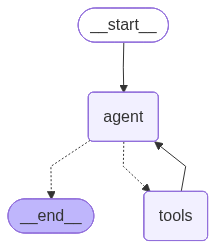

开始执行 Agent 闭环逻辑...

================================ Human Message =================================

深圳的天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_8d53b18e4ab24a239f89e2)
 Call ID: call_8d53b18e4ab24a239f89e2
  Args:
    location: 深圳
================================= Tool Message =================================
Name: get_weather

20° 有雾霾
================================== Ai Message ==================================

深圳目前的天气是20°C，有雾霾。建议减少户外活动，注意防护。


In [8]:
from langgraph.graph import StateGraph, MessagesState
from IPython.display import Image,display
# 1. 定义图
builder = StateGraph(MessagesState)
builder.add_node("agent", call_model)
builder.add_node("tools", tool_node) # 这里的 tool_node 就是你定义好的那个
builder.set_entry_point("agent")
builder.add_conditional_edges("agent", should_continue,{
        "tools": "tools",  # 如果 should_continue 返回 "tools"，去 tools 节点
        END: END          # 如果 should_continue 返回 END，结束流程
    })
builder.add_edge("tools", "agent")
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))
# 2. 运行
# 这种方式下，Graph 会自动为节点注入所有缺少的 Config 键
inputs = {"messages": [HumanMessage(content="深圳的天气如何？")]}

print("开始执行 Agent 闭环逻辑...\n")
for chunk in graph.stream(inputs, stream_mode="values"):
    # 提取当前状态中的最后一条消息
    latest_message = chunk["messages"][-1]
    latest_message.pretty_print()